# Adaline

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = data.data
y = data.target

y = np.where(y == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [23]:
unique, counts = np.unique(y_train, return_counts=True)
class_balance = dict(zip(unique, counts))
print("Class balance in training set:", class_balance)

print("Mean of normalized training features:", np.mean(X_train, axis=0))
print("Standard deviation of normalized training features:", np.std(X_train, axis=0))

Class balance in training set: {np.int64(-1): np.int64(149), np.int64(1): np.int64(249)}
Mean of normalized training features: [0.34097686 0.3934788  0.3354675  0.21987658 0.4762132  0.29004863
 0.20804664 0.24591726 0.37726384 0.26719581 0.10776615 0.186117
 0.09940247 0.06384701 0.2438146  0.21937408 0.07885295 0.22122513
 0.23368513 0.09812615 0.29987978 0.36019517 0.28550242 0.1742644
 0.40519742 0.21934287 0.2430143  0.39690461 0.26155516 0.18810272]
Standard deviation of normalized training features: [0.17010245 0.17366008 0.17095015 0.15529055 0.15095743 0.17453327
 0.18288554 0.19466764 0.14152291 0.1443251  0.10631729 0.12190517
 0.09929176 0.09302923 0.13219655 0.1614375  0.07207199 0.1109103
 0.15250513 0.09101003 0.17641154 0.16363909 0.17140957 0.14675146
 0.15162475 0.14888728 0.17466658 0.22599224 0.12489595 0.11763507]


In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

class Adaline:
    def __init__(self, lr, l2_lambda=0.0):
        self.lr = lr
        self.l2_lambda = l2_lambda

    def update_params(self, x, net, target):
        self.w = self.w - self.lr * (x.T @ (net - target) + self.l2_lambda * self.w)
        self.b = self.b - self.lr * np.sum(net - target)

    def train(self, x, y, epochs, early_stop=False):
        y = y.reshape(-1,1)
        self.w = np.random.rand(x.shape[1],1)
        self.b = np.random.rand()
        self.loss_history = []
        self.acc_history = []
        best_loss = np.inf
        best_w, best_b = None, None

        for epoch in range(epochs):
            net = x @ self.w + self.b
            diff = net - y
            sse = (diff.T @ diff).item()
            self.loss_history.append(sse)

            pred = np.where(net >= 0,1,-1)
            acc = np.mean(pred == y)
            self.acc_history.append(acc)

            if early_stop and sse > best_loss:
                print("Early stopping at epoch", epoch)
                break
            elif sse < best_loss:
                best_loss = sse
                best_w = self.w.copy()
                best_b = self.b

            self.update_params(x, net, y)

        self.w, self.b = best_w, best_b
        self.last_sse = best_loss

    def report(self, x_test, y_test):
        net = x_test @ self.w + self.b
        y_pred = np.where(net >= 0, 1, -1)
        return {
            "confusion_matrix": confusion_matrix(y_test, y_pred),
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
            "f1_score": f1_score(y_test, y_pred),
        }
    def net(self, x):
      return x @ self.w + self.b

    def predict(self, x):
        net = x @ self.w + self.b
        return np.where(net >= 0, 1, -1)

    def acc_loss_history(self):
      return self.acc_history, self.loss_history


In [25]:
learning_rates = [0.001, 0.005, 0.02]
early_stop_options = [False, True]
models = {}
best_model = None
best_acc = -1
best_config = (None, None)

for lr in learning_rates:
    for es in early_stop_options:
        model = Adaline(lr=lr, l2_lambda = 0.01)
        model.train(X_train, y_train, epochs=50, early_stop=es)
        report = model.report(X_test, y_test)

        models[(lr, es)] = model

        metric = report["accuracy"]
        if metric > best_acc:
            best_acc = metric
            best_model = model
            best_config = (lr, es)

print("Best Model Configuration:")
print("Learning Rate:", best_config[0])
print("Early Stop:", best_config[1])
print(best_model.report(X_test, y_test))
acc, loss = best_model.acc_loss_history()
print("Loss: \n", loss)
print("Accuracy: \n", acc)

Early stopping at epoch 1
Early stopping at epoch 1
Best Model Configuration:
Learning Rate: 0.001
Early Stop: True
{'confusion_matrix': array([[ 53,  10],
       [  2, 106]]), 'accuracy': 0.9298245614035088, 'precision': 0.9137931034482759, 'recall': 0.9814814814814815, 'f1_score': 0.9464285714285714}
Loss: 
 [9089.153262875425, 1604.1230832121853, 627.685865577104, 467.0445687899051, 413.08499979473913, 376.87180787169467, 346.722216581103, 320.65350465924934, 297.96360928354756, 278.17377986545335, 260.88778037968365, 245.76664655224747, 232.51887958833902, 220.89351900586274, 210.6743887454528, 201.67518562108862, 193.73527109186793, 186.71606218503595, 180.4979358933941, 174.97757333219687, 170.06568082607836, 165.6850340121431, 161.76879882755858, 158.25908985138585, 155.1057321462065, 152.26519759566884, 149.69969089088897, 147.37636387676298, 145.26664001666353, 143.34563334353334, 141.5916485003096, 139.98575038671953, 138.51139356896593, 137.1541030131503, 135.9011989062783, 

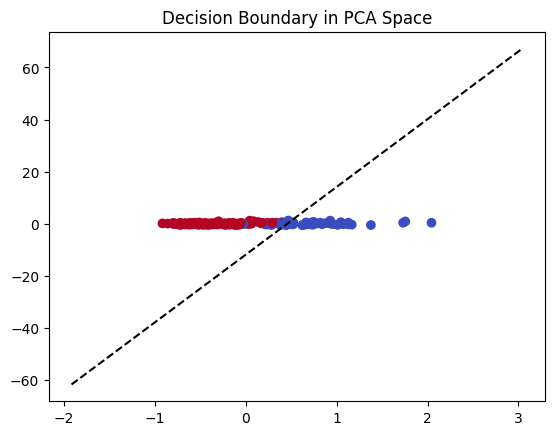

In [34]:
pca = PCA(n_components=2)
X_train_2d = pca.fit(X_train)
X_test_2d = pca.transform(X_test)
w_2d = pca.transform(best_model.w.T)[0]
b = best_model.b
best_pred = best_model.predict(X_test)

x_min, x_max = X_test_2d[:,0].min()-1, X_test_2d[:,0].max()+1
xs = np.linspace(x_min, x_max, 100)
ys = -(w_2d[0]/w_2d[1])*xs - (b/w_2d[1])

plt.figure()
plt.scatter(X_test_2d[:,0], X_test_2d[:,1], c=best_pred, cmap='coolwarm')
plt.plot(xs, ys, 'k--')
plt.title("Decision Boundary in PCA Space")
plt.show()



In [31]:
best_report = best_model.report(X_test, y_test)
cm = best_report["confusion_matrix"]
FP = np.where((y_test == -1) & (best_pred == 1))[0][:3]
FN = np.where((y_test == 1) & (best_pred == -1))[0][:3]
print("False Positive samples indices:", FP)
print("False Negative samples indices:", FN)


False Positive samples indices: [1 1 1]
False Negative samples indices: [0 0 0]


In [32]:
log_reg = LogisticRegression().fit(X_train, y_train)
lda = LinearDiscriminantAnalysis().fit(X_train, y_train)

def evaluate(model):
    pred = model.predict(X_test)
    return [
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred)
    ]

baseline = {
    "Adaline": [best_report["accuracy"], best_report["precision"], best_report["recall"], best_report["f1_score"]],
    "Logistic Regression": evaluate(log_reg),
    "LDA": evaluate(lda)
}

print("\nComparison Table: [Accuracy, Precision, Recall, F1]")
for k,v in baseline.items():
    print(k, ":", v)




Comparison Table: [Accuracy, Precision, Recall, F1]
Adaline : [0.9298245614035088, 0.9137931034482759, 0.9814814814814815, 0.9464285714285714]
Logistic Regression : [0.9532163742690059, 0.9385964912280702, 0.9907407407407407, 0.963963963963964]
LDA : [0.9707602339181286, 0.9557522123893806, 1.0, 0.9773755656108597]


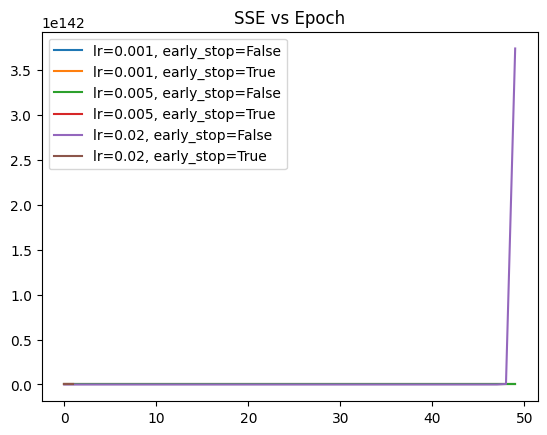

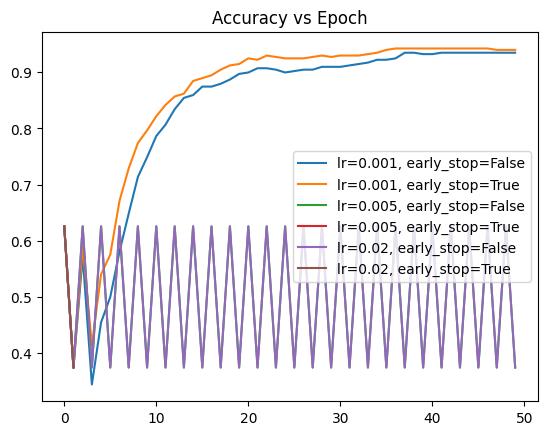

In [33]:
plt.figure()
for (lr, es), m in models.items():
    label = f"lr={lr}, early_stop={es}"
    plt.plot(m.loss_history, label=label)
plt.title("SSE vs Epoch")
plt.legend()
plt.show()

plt.figure()
for (lr, es), m in models.items():
    label = f"lr={lr}, early_stop={es}"
    plt.plot(m.acc_history, label=label)
plt.title("Accuracy vs Epoch")
plt.legend()
plt.show()

# Madaline

In [34]:
class Madaline:
    @staticmethod
    def sign(x):
        return np.where(x >= 0, 1, -1)

    def __init__(self, lr, m, n_features, l2_lambda=0.0):
        self.lr = lr
        self.l2_lambda = l2_lambda
        self.m = m
        self.w1 = np.random.randn(n_features, m) * 0.1
        self.b1 = np.zeros((1, m))
        self.w2 = np.random.randn(m, 1) * 0.1
        self.b2 = np.zeros((1,1))

    def forward(self, X):
        net1 = X @ self.w1 + self.b1
        y1 = self.sign(net1)
        net2 = y1 @ self.w2 + self.b2
        y_pred = self.sign(net2)
        return net1, y1, net2, y_pred

    def update_rule_II(self, x_i, y_i, hidden_out, hidden_net):
        candidates = []
        for j in range(self.m):
            flipped = hidden_out.copy()
            flipped[0, j] *= -1
            new_net2 = flipped @ self.w2 + self.b2
            new_out = self.sign(new_net2)[0,0]
            if new_out == y_i:
                candidates.append(j)

        if candidates:
            best_j = min(candidates, key=lambda j: abs(hidden_net[0, j]))
            target_h = -hidden_out[0, best_j]
            error_h = target_h - hidden_out[0, best_j]
            self.w1[:, best_j] += self.lr * error_h * x_i[0] - self.lr * self.l2_lambda * self.w1[:, best_j]
            self.b1[0, best_j] += self.lr * error_h
            return

        error = y_i - (hidden_out @ self.w2 + self.b2)[0,0]
        self.w2 += self.lr * error * hidden_out.T - self.lr * self.l2_lambda * self.w2
        self.b2 += self.lr * error

    def train(self, X, y, epochs):
        y = np.where(y == 0, -1, 1).reshape(-1, 1)
        for epoch in range(epochs):
            errors = 0
            for i in range(len(X)):
                x_i = X[i].reshape(1, -1)
                hidden_net, hidden_out, net2, y_pred = self.forward(x_i)
                if y_pred[0,0] != y[i,0]:
                    errors += 1
                    self.update_rule_II(x_i, y[i,0], hidden_out, hidden_net)

            _, _, _, y_all = self.forward(X)
            sse = np.sum((y_all - y) ** 2)
            print(f"Epoch {epoch+1}: SSE = {sse:.4f}, Errors = {errors}")
            if errors == 0:
                print("Training converged.")
                break

    def predict(self, X):
        _, _, net2, _ = self.forward(X)
        return net2.flatten()

    def report(self, x_test, y_test):
        y_test_bin = np.where(y_test == 0, -1, 1)
        y_pred_net = self.predict(x_test)
        y_pred = np.sign(y_pred_net)
        return {
            "confusion_matrix": confusion_matrix(y_test_bin, y_pred),
            "accuracy": accuracy_score(y_test_bin, y_pred),
            "precision": precision_score(y_test_bin, y_pred),
            "recall": recall_score(y_test_bin, y_pred),
            "f1_score": f1_score(y_test_bin, y_pred),
            "roc_auc": roc_auc_score(y_test_bin, y_pred_net)
        }

    def plot_decision_boundary(self, X, y, title):
        x_min, x_max = 0, 1  # since MinMax scaled
        y_min, y_max = 0, 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
        Z_net = self.predict(np.c_ [xx.ravel(), yy.ravel()])
        Z = np.sign(Z_net).reshape(xx.shape)
        plt.contourf(xx, yy, Z, alpha=0.8, cmap='coolwarm')
        plt.scatter(X[:,0], X[:,1], c=y, edgecolors='k', cmap='coolwarm')
        # Mark misclassified
        y_pred = np.sign(self.predict(X))
        mis = y_pred != np.where(y == 0, -1, 1)
        plt.scatter(X[mis,0], X[mis,1], marker='x', color='black')
        # Plot hidden hyperplanes
        for j in range(self.m):
            x_line = np.linspace(x_min, x_max, 100)
            if self.w1[1, j] != 0:
                y_line = - (self.w1[0, j] * x_line + self.b1[0, j]) / self.w1[1, j]
                plt.plot(x_line, y_line, 'g--', label=f'Hidden {j+1}' if j==0 else None)
        plt.title(title)
        plt.legend()
        plt.show()

In [35]:
from sklearn.datasets import make_moons, make_circles
moons_X, moons_y = make_moons(n_samples=600, noise=0.25, random_state=0)
scaler = MinMaxScaler()
moons_X = scaler.fit_transform(moons_X)
moons_x_train, moons_x_test, moons_y_train, moons_y_test = train_test_split(moons_X, moons_y, test_size=0.3, random_state=0)


circles_X, circles_y = make_circles(n_samples=600, noise=0.10, random_state=0)
scaler = MinMaxScaler()
circles_X = scaler.fit_transform(circles_X)
circles_x_train, circles_x_test, circles_y_train, circles_y_test = train_test_split(circles_X, circles_y, test_size=0.3, random_state=0)


In [36]:
hidden_layers = [3, 5]
lr =0.001
l2_lambda = [0.0, 0.001]
def eval_models(x_train, y_train, x_test, y_test):
  models = {}
  best_model = None
  best_acc = -1
  best_config = (None, None)

  for m in hidden_layers:
     for lam in l2_lambda:
         print(f"\nTraining model with m={m}, lambda={lam}")
         model = Madaline(lr=lr, l2_lambda=lam, n_features=2, m=m)
         model.train(x_train, y_train, epochs=50)

         report = model.report(x_test, y_test)  # ✅ اصلاح شد
         models[(m, lam)] = model

         metric = report["accuracy"]
         if metric > best_acc:
             best_acc = metric
             best_model = model
             best_config = (lr, lam)

  print("\n✅ Best Model Configuration:")
  print("Learning Rate:", best_config[0])
  print("L2 Lambda:", best_config[1])
  print(best_model.report(x_test, y_test))

  return models, best_model

In [37]:
#moons
eval_models(moons_x_train, moons_y_train, moons_x_test, moons_y_test)


Training model with m=3, lambda=0.0
Epoch 1: SSE = 248.0000, Errors = 55
Epoch 2: SSE = 208.0000, Errors = 55
Epoch 3: SSE = 200.0000, Errors = 56
Epoch 4: SSE = 188.0000, Errors = 51
Epoch 5: SSE = 224.0000, Errors = 50
Epoch 6: SSE = 224.0000, Errors = 52
Epoch 7: SSE = 220.0000, Errors = 54
Epoch 8: SSE = 268.0000, Errors = 59
Epoch 9: SSE = 224.0000, Errors = 58
Epoch 10: SSE = 280.0000, Errors = 65
Epoch 11: SSE = 220.0000, Errors = 62
Epoch 12: SSE = 332.0000, Errors = 62
Epoch 13: SSE = 232.0000, Errors = 62
Epoch 14: SSE = 368.0000, Errors = 73
Epoch 15: SSE = 272.0000, Errors = 70
Epoch 16: SSE = 280.0000, Errors = 68
Epoch 17: SSE = 436.0000, Errors = 79
Epoch 18: SSE = 444.0000, Errors = 74
Epoch 19: SSE = 396.0000, Errors = 76
Epoch 20: SSE = 416.0000, Errors = 72
Epoch 21: SSE = 396.0000, Errors = 70
Epoch 22: SSE = 400.0000, Errors = 74
Epoch 23: SSE = 416.0000, Errors = 74
Epoch 24: SSE = 416.0000, Errors = 74
Epoch 25: SSE = 416.0000, Errors = 74
Epoch 26: SSE = 444.00

({(3, 0.0): <__main__.Madaline at 0x7f87a14c1a60>,
  (3, 0.001): <__main__.Madaline at 0x7f87a3f11940>,
  (5, 0.0): <__main__.Madaline at 0x7f87a14c1c40>,
  (5, 0.001): <__main__.Madaline at 0x7f87a3f139e0>},
 <__main__.Madaline at 0x7f87a14c1a60>)

In [13]:
eval_models(circles_x_train, circles_y_train, circles_x_test, circles_y_test)


Training model with m=3, lambda=0.0
Epoch 1: SSE = 868.0000, Errors = 211
Epoch 2: SSE = 848.0000, Errors = 207
Epoch 3: SSE = 928.0000, Errors = 206
Epoch 4: SSE = 880.0000, Errors = 218
Epoch 5: SSE = 924.0000, Errors = 218
Epoch 6: SSE = 916.0000, Errors = 210
Epoch 7: SSE = 912.0000, Errors = 212
Epoch 8: SSE = 916.0000, Errors = 214
Epoch 9: SSE = 884.0000, Errors = 216
Epoch 10: SSE = 844.0000, Errors = 210
Epoch 11: SSE = 852.0000, Errors = 218
Epoch 12: SSE = 884.0000, Errors = 214
Epoch 13: SSE = 880.0000, Errors = 212
Epoch 14: SSE = 916.0000, Errors = 216
Epoch 15: SSE = 920.0000, Errors = 214
Epoch 16: SSE = 880.0000, Errors = 226
Epoch 17: SSE = 884.0000, Errors = 198
Epoch 18: SSE = 848.0000, Errors = 216
Epoch 19: SSE = 848.0000, Errors = 215
Epoch 20: SSE = 840.0000, Errors = 211
Epoch 21: SSE = 916.0000, Errors = 216
Epoch 22: SSE = 880.0000, Errors = 226
Epoch 23: SSE = 884.0000, Errors = 214
Epoch 24: SSE = 920.0000, Errors = 210
Epoch 25: SSE = 848.0000, Errors = 2

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Epoch 2: SSE = 716.0000, Errors = 191
Epoch 3: SSE = 680.0000, Errors = 196
Epoch 4: SSE = 796.0000, Errors = 200
Epoch 5: SSE = 656.0000, Errors = 193
Epoch 6: SSE = 876.0000, Errors = 213
Epoch 7: SSE = 868.0000, Errors = 208
Epoch 8: SSE = 916.0000, Errors = 206
Epoch 9: SSE = 900.0000, Errors = 218
Epoch 10: SSE = 880.0000, Errors = 224
Epoch 11: SSE = 888.0000, Errors = 208
Epoch 12: SSE = 916.0000, Errors = 218
Epoch 13: SSE = 904.0000, Errors = 210
Epoch 14: SSE = 880.0000, Errors = 210
Epoch 15: SSE = 884.0000, Errors = 214
Epoch 16: SSE = 896.0000, Errors = 206
Epoch 17: SSE = 848.0000, Errors = 211
Epoch 18: SSE = 880.0000, Errors = 209
Epoch 19: SSE = 896.0000, Errors = 214
Epoch 20: SSE = 892.0000, Errors = 226
Epoch 21: SSE = 848.0000, Errors = 202
Epoch 22: SSE = 936.0000, Errors = 208
Epoch 23: SSE = 880.0000, Errors = 214
Epoch 24: SSE = 880.0000, Errors = 214
Epoch 25: SSE = 876.0000, Errors = 226
Epoch 26: SSE = 848.0000, Errors = 202
Epoch 27: SSE = 848.0000, Errors 

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


({(3, 0.0): <__main__.Madaline at 0x7f87a4a733e0>,
  (3, 0.001): <__main__.Madaline at 0x7f87a5543260>,
  (5, 0.0): <__main__.Madaline at 0x7f87a4bfa5d0>,
  (5, 0.001): <__main__.Madaline at 0x7f87a62404a0>},
 <__main__.Madaline at 0x7f87a4a733e0>)

In [56]:
print(moons_x_train.shape)

(420, 2)
